# Does Pre-Release Situation Mix Affect Receiver Residual Reliability?

The prior reliability check found modest within-2023 repeatability. This experiment asks whether systematic residual patterns associated with the situation around the receiver affect that repeatability. The dynamic Ridge target, predictions, and route residuals stay fixed. We only add a diagnostic context adjustment, trained on one group of games and applied to another.

The adjustment uses coarse categories for down, distance, field position, separation and lateral location at the start of the input window, nearest-defender relative position, and receiver starting speed. It contains no receiver identity, route labels, route depth, or post-release information. The 2023 source does not provide a directly comparable PFF alignment label, so lateral location is only a tracking-based alignment proxy. The adjuster is a fixed-penalty additive Ridge model (alpha=25); this is a sensitivity test, not a tuned replacement metric.

In [1]:
from pathlib import Path
import statistics
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from IPython.display import HTML, SVG, display
from separation_over_expected.context_mix_audit import (
    CONTEXT_FEATURES,
    DEFAULT_COHORTS,
    audit_context_mix,
)
from separation_over_expected.cross_season import load_cross_season_wr_rows
from separation_over_expected.reports import read_csv_rows, write_csv

LEGACY_ROUTES = PROJECT_ROOT / "data/processed/dynamic_features/route_level_snap_to_release_dynamic.csv"
BDB2023_ROUTES = PROJECT_ROOT / "data/processed/bdb2026/route_level_input_window_2023_dynamic.csv"
NFLVERSE_PBP = PROJECT_ROOT.parent / "data/big_data_bowl_2026/nflverse_play_by_play_2023.csv"
PREDICTIONS = PROJECT_ROOT / "data/processed/cross_season_receiver_reliability/route_predictions.csv"
OUTPUT = PROJECT_ROOT / "data/processed/context_mix_audit"
OUTPUT_FILES = {
    "split": OUTPUT / "split_reliability.csv",
    "fit": OUTPUT / "context_fit_metrics.csv",
    "summary": OUTPUT / "reliability_summary.csv",
}
required_inputs = (LEGACY_ROUTES, BDB2023_ROUTES, NFLVERSE_PBP, PREDICTIONS)
missing_inputs = [str(path) for path in required_inputs if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(f"Required local inputs are missing: {missing_inputs}")

_, contexts_2023, join_checks = load_cross_season_wr_rows(
    LEGACY_ROUTES, BDB2023_ROUTES, NFLVERSE_PBP, require_dynamic=True
)
predictions = read_csv_rows(PREDICTIONS)
join_checks

{'legacy_wr_routes': 20413,
 'bdb2023_wr_routes': 38002,
 'bdb2023_plays_without_context': 0,
 'yardline_max_absolute_error': 0.0}

## Cross-fit the context correction across whole games

For each of 100 week-balanced A/B game assignments, the context model learns residual patterns from A and predicts them in B, then trains on B and predicts A. A and B are scored with the same eligible receivers and the same route/game cutoffs. We report both the raw and context-adjusted receiver half correlations, paired changes, and a held-out route residual RMSE check.

The fixed cohort grid is 10 routes/3 games, 20 routes/5 games, and 30 routes/5 games per half. The primary comparison is 20/5. Percentile ranges across splits show assignment sensitivity; pooled bootstrap intervals resample receivers within each split and combine those draws across the repeated assignments.

In [2]:
if all(path.exists() for path in OUTPUT_FILES.values()):
    split_rows = read_csv_rows(OUTPUT_FILES["split"])
    context_fit_rows = read_csv_rows(OUTPUT_FILES["fit"])
    summary_rows = read_csv_rows(OUTPUT_FILES["summary"])
else:
    split_rows, context_fit_rows, summary_rows = audit_context_mix(
        contexts_2023,
        predictions,
        cohorts=DEFAULT_COHORTS,
        split_seeds=100,
        bootstrap_samples=300,
        seed=42,
        ridge_alpha=25.0,
    )
    OUTPUT.mkdir(parents=True, exist_ok=True)
    write_csv(OUTPUT_FILES["split"], list(split_rows[0]), split_rows)
    write_csv(OUTPUT_FILES["fit"], list(context_fit_rows[0]), context_fit_rows)
    write_csv(OUTPUT_FILES["summary"], list(summary_rows[0]), summary_rows)
len(contexts_2023), len(predictions), len(split_rows), CONTEXT_FEATURES

(38002,
 58415,
 300,
 ('down',
  'yards_to_go_bin',
  'yardline_bin',
  'start_separation_bin',
  'start_width_bin',
  'defender_depth_leverage_bin',
  'defender_width_leverage_bin',
  'receiver_start_speed_bin'))

In [3]:
def ci(row, field):
    return f'[{float(row[f"{field}_bootstrap_ci_lower"]):.2f}, {float(row[f"{field}_bootstrap_ci_upper"]):.2f}]'

table = []
for row in summary_rows:
    table.append({
        "routes / games per half": f'{row["min_routes_per_half"]} / {row["min_games_per_half"]}',
        "eligible receivers": f'{float(row["receivers_median"]):.0f} median '
                              f'({float(row["receivers_p10"]):.0f}–{float(row["receivers_p90"]):.0f})',
        "raw Pearson": f'{float(row["pearson_raw_median"]):.2f} '
                       f'({float(row["pearson_raw_p10"]):.2f}–{float(row["pearson_raw_p90"]):.2f})',
        "adjusted Pearson": f'{float(row["pearson_adjusted_median"]):.2f} '
                             f'({float(row["pearson_adjusted_p10"]):.2f}–{float(row["pearson_adjusted_p90"]):.2f})',
        "paired Δ Pearson": f'{float(row["pearson_change_median"]):+.2f} '
                            f'{ci(row, "pearson_change")}',
        "raw Spearman": f'{float(row["spearman_raw_median"]):.2f}',
        "adjusted Spearman": f'{float(row["spearman_adjusted_median"]):.2f}',
        "paired Δ Spearman": f'{float(row["spearman_change_median"]):+.2f} '
                             f'{ci(row, "spearman_change")}',
    })
display(table)

[{'routes / games per half': '10 / 3',
  'eligible receivers': '161 median (154–166)',
  'raw Pearson': '0.23 (0.12–0.33)',
  'adjusted Pearson': '0.25 (0.15–0.35)',
  'paired Δ Pearson': '+0.03 [-0.05, 0.11]',
  'raw Spearman': '0.22',
  'adjusted Spearman': '0.22',
  'paired Δ Spearman': '-0.00 [-0.07, 0.06]'},
 {'routes / games per half': '20 / 5',
  'eligible receivers': '115 median (107–122)',
  'raw Pearson': '0.27 (0.13–0.37)',
  'adjusted Pearson': '0.25 (0.12–0.35)',
  'paired Δ Pearson': '-0.03 [-0.11, 0.08]',
  'raw Spearman': '0.27',
  'adjusted Spearman': '0.25',
  'paired Δ Spearman': '-0.03 [-0.11, 0.06]'},
 {'routes / games per half': '30 / 5',
  'eligible receivers': '108 median (100–115)',
  'raw Pearson': '0.30 (0.19–0.39)',
  'adjusted Pearson': '0.27 (0.17–0.36)',
  'paired Δ Pearson': '-0.04 [-0.11, 0.04]',
  'raw Spearman': '0.30',
  'adjusted Spearman': '0.26',
  'paired Δ Spearman': '-0.03 [-0.11, 0.05]'}]

## Does situation context predict held-out residual patterns?

This is a prerequisite for interpreting any reliability change. We compare the centered residual RMSE on held-out games before and after subtracting the context model's predicted residual pattern. The adjustment is centered within the held-out half so a common season-level bias cannot masquerade as situation-mix signal.

In [4]:
fit_metrics = {
    key: [float(row[key]) for row in context_fit_rows]
    for key in (
        "raw_centered_residual_rmse",
        "adjusted_centered_residual_rmse",
        "rmse_change_adjusted_minus_raw",
    )
}
fit_summary = {
    key: {
        "median": statistics.median(values),
        "p10": sorted(values)[int(.10 * (len(values) - 1))],
        "p90": sorted(values)[int(.90 * (len(values) - 1))],
    }
    for key, values in fit_metrics.items()
}
display(fit_summary)

{'raw_centered_residual_rmse': {'median': 1.90180573,
  'p10': 1.90165429,
  'p90': 1.9018278},
 'adjusted_centered_residual_rmse': {'median': 1.876717465,
  'p10': 1.87581114,
  'p90': 1.87794242},
 'rmse_change_adjusted_minus_raw': {'median': -0.02504153,
  'p10': -0.02599953,
  'p90': -0.02388217}}

## Visual comparison

Points show median receiver repeatability across game assignments. Thin whiskers show the 10th–90th percentile assignment range; thick bars show the pooled bootstrap interval for the paired change. A context correction is useful only if it predicts held-out residual patterns and meaningfully changes receiver repeatability. A change alone is not evidence of receiver skill.

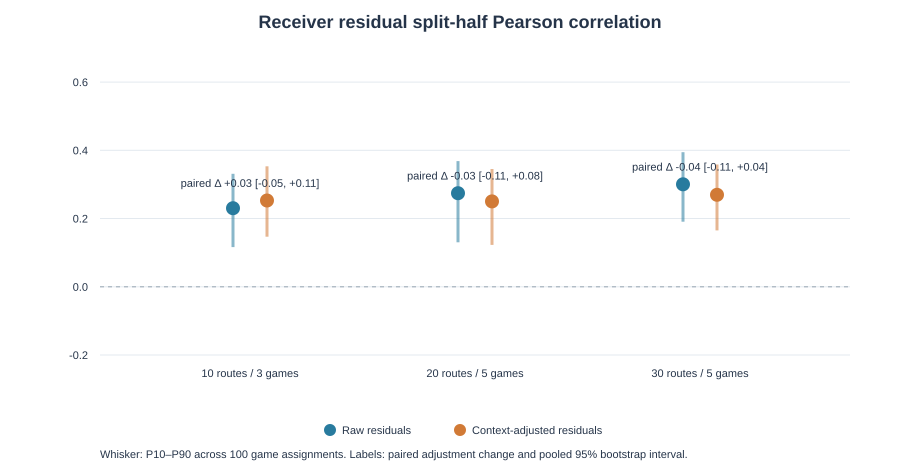

In [5]:
def reliability_plot(rows, width=920, height=470):
    left, right, top, bottom = 100, 850, 65, 355
    y_min, y_max = -0.2, 0.65
    y = lambda value: bottom - (float(value) - y_min) / (y_max - y_min) * (bottom - top)
    x_centers = [250, 475, 700]
    colors = {"raw": "#287b9e", "adjusted": "#d17a36"}
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e3e9ef}.range{stroke-width:3;opacity:.55}.zero{stroke:#9aa6b2;stroke-dasharray:4 4}</style>',
        '<text x="460" y="28" text-anchor="middle" font-size="18" font-weight="bold">Receiver residual split-half Pearson correlation</text>',
    ]
    for tick in (-.2, 0, .2, .4, .6):
        yy = y(tick)
        parts.extend([
            f'<line class="grid" x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}"/>',
            f'<text x="{left-12}" y="{yy+4:.1f}" text-anchor="end" font-size="11">{tick:.1f}</text>',
        ])
    parts.append(f'<line class="zero" x1="{left}" y1="{y(0):.1f}" x2="{right}" y2="{y(0):.1f}"/>')
    for center, row in zip(x_centers, rows):
        for offset, version in ((-17, "raw"), (17, "adjusted")):
            x = center + offset
            median = float(row[f"pearson_{version}_median"])
            low, high = float(row[f"pearson_{version}_p10"]), float(row[f"pearson_{version}_p90"])
            parts.extend([
                f'<line class="range" x1="{x}" y1="{y(low):.1f}" x2="{x}" y2="{y(high):.1f}" stroke="{colors[version]}"/>',
                f'<circle cx="{x}" cy="{y(median):.1f}" r="7" fill="{colors[version]}"><title>{version}: median {median:.3f}; assignment range {low:.3f} to {high:.3f}</title></circle>',
            ])
        delta = float(row["pearson_change_median"])
        ci_low, ci_high = float(row["pearson_change_bootstrap_ci_lower"]), float(row["pearson_change_bootstrap_ci_upper"])
        parts.append(f'<text x="{center}" y="{y(max(float(row["pearson_raw_median"]), float(row["pearson_adjusted_median"]))+0.04):.1f}" text-anchor="middle" font-size="11">paired Δ {delta:+.2f} [{ci_low:+.2f}, {ci_high:+.2f}]</text>')
        parts.append(f'<text x="{center}" y="{bottom+22}" text-anchor="middle" font-size="11">{row["min_routes_per_half"]} routes / {row["min_games_per_half"]} games</text>')
    parts.extend([
        '<circle cx="330" cy="430" r="6" fill="#287b9e"/><text x="342" y="434" font-size="11">Raw residuals</text>',
        '<circle cx="460" cy="430" r="6" fill="#d17a36"/><text x="472" y="434" font-size="11">Context-adjusted residuals</text>',
        '<text x="100" y="458" font-size="11">Whisker: P10–P90 across 100 game assignments. Labels: paired adjustment change and pooled 95% bootstrap interval.</text>',
        '</svg>',
    ])
    return "".join(parts)

display(SVG(reliability_plot(summary_rows)))

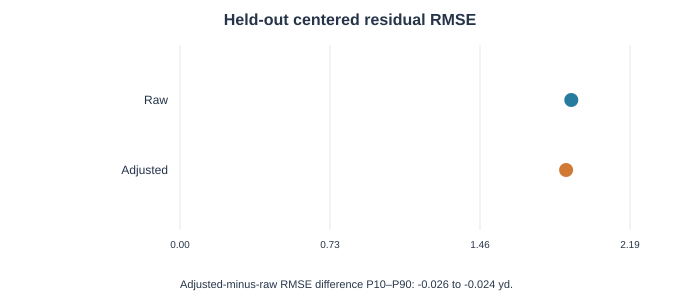

In [6]:
def rmse_plot(summary, width=700, height=300):
    raw = summary["raw_centered_residual_rmse"]
    adjusted = summary["adjusted_centered_residual_rmse"]
    low = summary["rmse_change_adjusted_minus_raw"]["p10"]
    high = summary["rmse_change_adjusted_minus_raw"]["p90"]
    max_value = max(raw["p90"], adjusted["p90"]) * 1.15
    left, right, top, bottom = 180, 630, 45, 230
    x = lambda value: left + float(value) / max_value * (right - left)
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}"><rect width="100%" height="100%" fill="white"/><style>text{{font-family:Arial,sans-serif;fill:#253449}}.grid{{stroke:#e3e9ef}}</style><text x="350" y="25" text-anchor="middle" font-size="16" font-weight="bold">Held-out centered residual RMSE</text>']
    for tick in range(4):
        value = max_value * tick / 3
        xx = x(value)
        parts.extend([f'<line class="grid" x1="{xx:.1f}" y1="{top}" x2="{xx:.1f}" y2="{bottom}"/>', f'<text x="{xx:.1f}" y="{bottom+18}" text-anchor="middle" font-size="10">{value:.2f}</text>'])
    for y_pos, label, value, color in ((100, "Raw", raw, "#287b9e"), (170, "Adjusted", adjusted, "#d17a36")):
        parts.extend([f'<text x="{left-12}" y="{y_pos+4}" text-anchor="end" font-size="12">{label}</text>', f'<line x1="{x(value["p10"]):.1f}" y1="{y_pos}" x2="{x(value["p90"]):.1f}" y2="{y_pos}" stroke="{color}" stroke-width="4" opacity=".55"/>', f'<circle cx="{x(value["median"]):.1f}" cy="{y_pos}" r="7" fill="{color}"/>'])
    parts.append(f'<text x="{left}" y="{height-12}" font-size="11">Adjusted-minus-raw RMSE difference P10–P90: {low:+.3f} to {high:+.3f} yd.</text></svg>')
    return "".join(parts)

display(SVG(rmse_plot(fit_summary)))

## Interpretation guide

Read the two results together. If context adjustment improves held-out residual RMSE and materially increases split-half receiver reliability, the original receiver scores were partly confounded by situation mix. If it improves residual RMSE but lowers repeatability, the adjusted scores remove a repeatable role/context component; that is a real tradeoff, not automatic evidence of improvement. If the context model does not improve held-out RMSE, there is little support for this particular context-bias explanation. The adjusted score remains a diagnostic and is not a causal estimate of receiver ability.

In this run, the correction reduces held-out centered residual RMSE by about 0.025 yards. At the primary 20-route/five-game cutoff, median Pearson repeatability shifts from 0.274 raw to 0.250 adjusted (paired change -0.027; pooled 95% interval [-0.112, 0.082]). Spearman changes by -0.025, also with an interval spanning zero. The context fields contain some predictive residual structure, but removing it does not improve receiver repeatability. It may remove repeatable role/context signal; this experiment cannot identify that signal as receiver skill.

In [7]:
primary = next(
    row for row in summary_rows
    if row["min_routes_per_half"] == "20" and row["min_games_per_half"] == "5"
)
context_rmse_change = fit_summary["rmse_change_adjusted_minus_raw"]
result = {
    "primary_cohort_receivers_median": round(float(primary["receivers_median"])),
    "raw_pearson_median": round(float(primary["pearson_raw_median"]), 3),
    "adjusted_pearson_median": round(float(primary["pearson_adjusted_median"]), 3),
    "paired_pearson_change": round(float(primary["pearson_change_median"]), 3),
    "paired_pearson_change_bootstrap_95": (
        round(float(primary["pearson_change_bootstrap_ci_lower"]), 3),
        round(float(primary["pearson_change_bootstrap_ci_upper"]), 3),
    ),
    "median heldout centered residual RMSE change": round(context_rmse_change["median"], 3),
    "RMSE change split P10-P90": (round(context_rmse_change["p10"], 3), round(context_rmse_change["p90"], 3)),
}
result

{'primary_cohort_receivers_median': 115,
 'raw_pearson_median': 0.274,
 'adjusted_pearson_median': 0.25,
 'paired_pearson_change': -0.027,
 'paired_pearson_change_bootstrap_95': (-0.112, 0.082),
 'median heldout centered residual RMSE change': -0.025,
 'RMSE change split P10-P90': (-0.026, -0.024)}